# 09 — Modelagem Preditiva com Validação Temporal em Cascata (Walk-Forward)

## 🎯 Por que este notebook existe e qual o erro corrigido do Notebook 08?

No **Notebook 08**, a divisão de dados utilizou o `train_test_split(..., test_size=0.25, random_state=42)` aleatório. Em dados tabulares estáticos, essa abordagem é padrão. Porém, em **finanças e séries temporais de dados em painel**, o sorteio aleatório introduz dois problemas metodológicos severos:

### 1. Vazamento Temporal (*Data Leakage* / Olhar para o Futuro)
* O split aleatório mistura linhas de diferentes anos. O modelo pode receber a **Petrobras em 2024 no treino** (sabendo como o ciclo de juros e câmbio se comportou) e ser avaliado na **Petrobras em 2022 no teste**.
* Na vida real, o modelo preditivo precisa aprender estritamente com o passado ($t \le k$) para projetar o futuro ($t = k+1$).

### 2. Vazamento Macroeconômico no Alvo de Preços (`ACAO_SOBE`)
* Como as variáveis macroeconômicas anuais (`IBOV_RETORNO_%`, `SELIC_ANO_%`, `DOLAR_VAR_%`) são idênticas para todas as empresas dentro de um mesmo ano, sortear 75% das empresas de 2023 e 2024 para o treino entrega ao modelo o comportamento da bolsa naqueles anos. Quando ele avalia os 25% restantes nos mesmos anos, a acurácia de `ACAO_SOBE` fica artificialmente inflada.

---

## 📈 A Solução: Validação em Cascata (*Expanding Window / Walk-Forward*)

Como nossa base contábil possui balanços fechados de **2021 a 2025** ($T = 5$ anos), existem **4 transições anuais** ($t \to t+1$) com gabarito conhecido:
* `2021 -> 2022` ($32$ empresas): **Base histórica inicial de treino** (não pode ser testada sem dados de 2020).
* `2022 -> 2023` ($40$ empresas): **Fold 1 de Teste** (Alvo 2023).
* `2023 -> 2024` ($41$ empresas): **Fold 2 de Teste** (Alvo 2024).
* `2024 -> 2025` ($43$ empresas): **Fold 3 de Teste** (Alvo 2025).

Portanto, executamos **exatamente 3 Folds de validação temporal fora da amostra** ($N_{\text{teste total}} = 40 + 41 + 43 = 124$ observações):

* **Fold 1 (Alvo 2023):** Treina em `2021->2022` ($32$ obs.) $\longrightarrow$ Testa em `2022->2023` ($40$ obs.)
* **Fold 2 (Alvo 2024):** Treina em `2021->2023` ($72$ obs.) $\longrightarrow$ Testa em `2023->2024` ($41$ obs.)
* **Fold 3 (Alvo 2025):** Treina em `2021->2024` ($113$ obs.) $\longrightarrow$ Testa em `2024->2025` ($43$ obs.)

> **Rigor Metodológico:** Avaliamos Acurácia, **Baseline da Classe Majoritária** (no treino e no teste), **Precisão, Recall, F1-Score**, **Matriz de Confusão** e o **Intervalo de Confiança de 95% (IC 95%)** para $N = 124$, além do comparativo direto **Antes (Split Aleatório) vs. Depois (Walk-Forward)** na mesma base limpa.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Configuração de estilo
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Carregar a base consolidada limpa e os clusters do Notebook 07
df = pd.read_csv('../data/processed/dados_consolidados_b3.csv')
df_clusters = pd.read_csv('../data/processed/clusters_empresas.csv')
df = df.merge(df_clusters, on='TICKER', how='left')
df.head()


In [2]:
# 1. Ordenar rigorosamente por Empresa e Ano (garante que o shift temporal funcione)
df = df.sort_values(by=['TICKER', 'ANO']).reset_index(drop=True)

# 2. Criar os alvos do próximo ano (t + 1)
df['ANO_ALVO'] = df['ANO'] + 1
df['ROE_PROX_ANO'] = df.groupby('TICKER')['ROE'].shift(-1)
df['COTACAO_PROX_ANO'] = df.groupby('TICKER')['COTACAO_FINAL_ANO'].shift(-1)

# 3. Transformar em alvo binário (1 = Subiu em ANO_ALVO, 0 = Caiu/Manteve)
df['ROE_SOBE'] = (df['ROE_PROX_ANO'] > df['ROE']).astype(int)
df['ACAO_SOBE'] = (df['COTACAO_PROX_ANO'] > df['COTACAO_FINAL_ANO']).astype(int)

# 4. Cenário macroeconômico oficial consolidado (2021 a 2025 — Fontes: BCB SGS 432/13522 e B3/Yahoo Finance)
# Nota de auditoria: Os valores de 2025 foram atualizados com os dados oficiais de fechamento de 31/12/2025
# (Selic Meta: 15,00% a.a., IPCA 12m: 4,26%, Ibovespa: +33,95%, Dólar: -11,36%), substituindo os antigos placeholders.
dados_macro = {
    'ANO':            [2021,   2022,  2023,   2024,   2025],
    'SELIC_ANO_%':    [9.25,  13.75, 11.75,  12.25,  15.00],
    'VAR_SELIC_PP':   [7.25,   4.50, -2.00,   0.50,   2.75],
    'IPCA_ANO_%':     [10.06,  5.79,  4.62,   4.83,   4.26],
    'IBOV_RETORNO_%': [-11.93, 4.69, 22.28, -10.37,  33.95],
    'DOLAR_VAR_%':    [7.47,  -5.32, -8.08,  27.35, -11.36]
}
df_macro = pd.DataFrame(dados_macro)
if 'SELIC_ANO_%' not in df.columns:
    df = df.merge(df_macro, on='ANO', how='left')

# 5. Transformar CLUSTER em colunas binárias (One-Hot Encoding)
df_completo = pd.get_dummies(df, columns=['CLUSTER'], dtype=int)

# Base de modelagem com gabarito conhecido (4 transições: 2021->2022, 2022->2023, 2023->2024, 2024->2025)
df_modelo = df_completo.dropna(subset=['ROE_PROX_ANO', 'COTACAO_PROX_ANO']).copy()

# 6. Definir a lista de FEATURES (13 variáveis explicativas no ano t)
cluster_cols = [c for c in df_modelo.columns if c.startswith('CLUSTER_')]
macro_cols = ['SELIC_ANO_%', 'VAR_SELIC_PP', 'IPCA_ANO_%', 'IBOV_RETORNO_%', 'DOLAR_VAR_%']
features = ['LUCRO_LIQUIDO_BI', 'PATRIMONIO_LIQUIDO_BI', 'ROE', 'COTACAO_FINAL_ANO'] + cluster_cols + macro_cols

print(f"Total de features ({len(features)}): {features}\n")
print("Transições (ANO_BASE -> ANO_ALVO) disponíveis com gabarito real:")
print(df_modelo.groupby(['ANO', 'ANO_ALVO']).size().rename('N_Empresas'))


Total de features (13): ['LUCRO_LIQUIDO_BI', 'PATRIMONIO_LIQUIDO_BI', 'ROE', 'COTACAO_FINAL_ANO', 'CLUSTER_0.0', 'CLUSTER_1.0', 'CLUSTER_2.0', 'CLUSTER_3.0', 'SELIC_ANO_%', 'VAR_SELIC_PP', 'IPCA_ANO_%', 'IBOV_RETORNO_%', 'DOLAR_VAR_%']

Transições (ANO_BASE -> ANO_ALVO) disponíveis com gabarito real:
ANO   ANO_ALVO
2021  2022        32
2022  2023        40
2023  2024        41
2024  2025        43
Name: N_Empresas, dtype: int64


In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# ==============================================================================
# 1. EXECUÇÃO DOS 3 FOLDS EM CASCATA (WALK-FORWARD VALIDATION)
# ==============================================================================
anos_alvo_teste = [2023, 2024, 2025]
alvos = ['ROE_SOBE', 'ACAO_SOBE']
metricas_folds = []
acumulado_wf = {}

for alvo in alvos:
    y_true_all, y_pred_all, y_dummy_all = [], [], []
    
    for idx_fold, ano_alvo in enumerate(anos_alvo_teste, start=1):
        treino = df_modelo[df_modelo['ANO_ALVO'] < ano_alvo]
        teste = df_modelo[df_modelo['ANO_ALVO'] == ano_alvo]
        
        X_train, y_train = treino[features], treino[alvo]
        X_test, y_test = teste[features], teste[alvo]
        
        modelo = Pipeline([
            ('scaler', StandardScaler()),
            ('rf', RandomForestClassifier(
                n_estimators=100, max_depth=4, min_samples_split=5,
                random_state=42, class_weight='balanced'
            ))
        ])
        modelo.fit(X_train, y_train)
        preds = modelo.predict(X_test)
        
        # Baselines por fold:
        # - Base_Dummy_Treino: chutar sempre a classe majoritária observada no TREINO (o que um classificador ingênuo honesto faz)
        # - Taxa_Maj_Teste: proporção da classe majoritária no próprio conjunto de TESTE (teto de um chute fixo no ano)
        classe_maj_treino = int(y_train.mode()[0])
        preds_dummy = np.full_like(y_test, classe_maj_treino)
        acc_dummy = accuracy_score(y_test, preds_dummy)
        taxa_maj_teste = max(y_test.mean(), 1.0 - y_test.mean())
        
        acc = accuracy_score(y_test, preds)
        prec = precision_score(y_test, preds, zero_division=0)
        rec = recall_score(y_test, preds, zero_division=0)
        f1 = f1_score(y_test, preds, zero_division=0)
        tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
        
        y_true_all.extend(y_test)
        y_pred_all.extend(preds)
        y_dummy_all.extend(preds_dummy)
        
        metricas_folds.append({
            'Alvo': alvo,
            'Fold': f"Fold {idx_fold}",
            'Ano_Alvo': ano_alvo,
            'Treino_Ate': ano_alvo - 1,
            'N_Treino': len(treino),
            'N_Teste': len(teste),
            'Acuracia': round(acc, 4),
            'Base_Dummy_Tr': round(acc_dummy, 4),
            'Taxa_Maj_Teste': round(taxa_maj_teste, 4),
            'Precisao': round(prec, 4),
            'Recall': round(rec, 4),
            'F1_Score': round(f1, 4),
            'Matriz_Confusao': f"[[{tn}, {fp}], [{fn}, {tp}]]"
        })
    
    # Métricas acumuladas nos 124 testes (Pooled Out-of-Sample) + Intervalo de Confiança 95%
    y_true_arr = np.array(y_true_all)
    y_pred_arr = np.array(y_pred_all)
    y_dummy_arr = np.array(y_dummy_all)
    
    acc_total = accuracy_score(y_true_arr, y_pred_arr)
    n_total = len(y_true_arr)
    erro_padrao = np.sqrt(acc_total * (1.0 - acc_total) / n_total)
    ic_95 = (acc_total - 1.96 * erro_padrao, acc_total + 1.96 * erro_padrao)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_true_arr, y_pred_arr).ravel()
    
    acumulado_wf[alvo] = {
        'N_Teste_Total': n_total,
        'Acuracia': acc_total,
        'IC_95_Min': ic_95[0],
        'IC_95_Max': ic_95[1],
        'Base_Dummy_Tr': accuracy_score(y_true_arr, y_dummy_arr),
        'Taxa_Maj_Teste': max(y_true_arr.mean(), 1.0 - y_true_arr.mean()),
        'Precisao': precision_score(y_true_arr, y_pred_arr, zero_division=0),
        'Recall': recall_score(y_true_arr, y_pred_arr, zero_division=0),
        'F1_Score': f1_score(y_true_arr, y_pred_arr, zero_division=0),
        'CM': f"[[{tn_t}, {fp_t}], [{fn_t}, {tp_t}]]"
    }

df_backtest = pd.DataFrame(metricas_folds)
print("📊 TABELA 1 — DESEMPENHO DETALHADO POR FOLD (WALK-FORWARD, 3 FOLDS, N=124):")
print(df_backtest.to_string(index=False))

# ==============================================================================
# 2. COMPARATIVO LADO A LADO: ANTES (SPLIT ALEATÓRIO) VS. DEPOIS (WALK-FORWARD)
# ==============================================================================
X_all = df_modelo[features]
X_tr_rnd, X_te_rnd, idx_tr_rnd, idx_te_rnd = train_test_split(
    X_all, df_modelo.index, test_size=0.25, random_state=42
)

comparativo_rows = []
for alvo in alvos:
    y_tr_r = df_modelo.loc[idx_tr_rnd, alvo]
    y_te_r = df_modelo.loc[idx_te_rnd, alvo]
    
    mod_rnd = Pipeline([
        ('scaler', StandardScaler()),
        ('rf', RandomForestClassifier(
            n_estimators=100, max_depth=4, min_samples_split=5,
            random_state=42, class_weight='balanced'
        ))
    ])
    mod_rnd.fit(X_tr_rnd, y_tr_r)
    pr_rnd = mod_rnd.predict(X_te_rnd)
    
    maj_tr_r = int(y_tr_r.mode()[0])
    acc_dummy_r = accuracy_score(y_te_r, np.full_like(y_te_r, maj_tr_r))
    taxa_maj_te_r = max(y_te_r.mean(), 1.0 - y_te_r.mean())
    tn_r, fp_r, fn_r, tp_r = confusion_matrix(y_te_r, pr_rnd).ravel()
    
    # Linha ANTES (Notebook 08 reproduzido na mesma base corrigida)
    comparativo_rows.append({
        'Alvo': alvo,
        'Metodo_Validacao': 'ANTES: Split Aleatório (Com Leakage)',
        'N_Teste': len(y_te_r),
        'Acuracia': f"{accuracy_score(y_te_r, pr_rnd):.2%}",
        'IC_95%': 'N/A (Amostra Viciada)',
        'Base_Dummy_Tr': f"{acc_dummy_r:.2%}",
        'Taxa_Maj_Teste': f"{taxa_maj_te_r:.2%}",
        'Precisao': f"{precision_score(y_te_r, pr_rnd):.2%}",
        'Recall': f"{recall_score(y_te_r, pr_rnd):.2%}",
        'F1_Score': f"{f1_score(y_te_r, pr_rnd):.2%}",
        'Matriz_Confusao': f"[[{tn_r}, {fp_r}], [{fn_r}, {tp_r}]]"
    })
    
    # Linha DEPOIS (Notebook 09 - Walk-Forward acumulado nos 3 folds)
    wf = acumulado_wf[alvo]
    comparativo_rows.append({
        'Alvo': alvo,
        'Metodo_Validacao': 'DEPOIS: Walk-Forward (3 Folds Sem Leakage)',
        'N_Teste': wf['N_Teste_Total'],
        'Acuracia': f"{wf['Acuracia']:.2%}",
        'IC_95%': f"[{wf['IC_95_Min']:.1%}, {wf['IC_95_Max']:.1%}]",
        'Base_Dummy_Tr': f"{wf['Base_Dummy_Tr']:.2%}",
        'Taxa_Maj_Teste': f"{wf['Taxa_Maj_Teste']:.2%}",
        'Precisao': f"{wf['Precisao']:.2%}",
        'Recall': f"{wf['Recall']:.2%}",
        'F1_Score': f"{wf['F1_Score']:.2%}",
        'Matriz_Confusao': wf['CM']
    })

df_comparativo = pd.DataFrame(comparativo_rows)
print("\n" + "=" * 115)
print("⚖️ TABELA 2 — COMPARATIVO ANTES (SPLIT ALEATÓRIO NO 08) VS. DEPOIS (WALK-FORWARD NO 09) NA MESMA BASE LIMPA:")
print("=" * 115)
print(df_comparativo.to_string(index=False))


📊 TABELA 1 — DESEMPENHO DETALHADO POR FOLD (WALK-FORWARD, 3 FOLDS, N=124):
     Alvo   Fold  Ano_Alvo  Treino_Ate  N_Treino  N_Teste  Acuracia  Base_Dummy_Tr  Taxa_Maj_Teste  Precisao  Recall  F1_Score     Matriz_Confusao
 ROE_SOBE Fold 1      2023        2022        32       40    0.6500         0.5250          0.5250    0.6667  0.5263    0.5882  [[16, 5], [9, 10]]
 ROE_SOBE Fold 2      2024        2023        72       41    0.6585         0.5122          0.5122    0.6364  0.7000    0.6667  [[13, 8], [6, 14]]
 ROE_SOBE Fold 3      2025        2024       113       43    0.5581         0.5116          0.5116    0.5417  0.6190    0.5778 [[11, 11], [8, 13]]
ACAO_SOBE Fold 1      2023        2022        32       40    0.4500         0.2500          0.7500    0.7222  0.4333    0.5417  [[5, 5], [17, 13]]
ACAO_SOBE Fold 2      2024        2023        72       41    0.3415         0.1951          0.8049    0.2121  0.8750    0.3415   [[7, 26], [1, 7]]
ACAO_SOBE Fold 3      2025        2024     

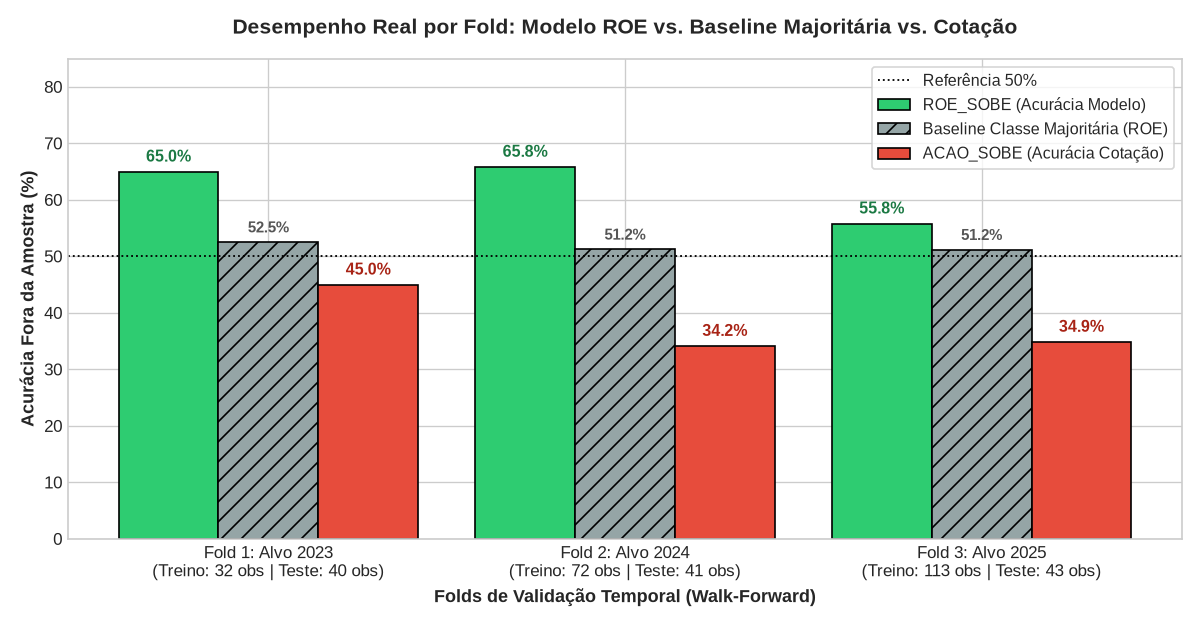

In [4]:
# Visualização Comparativa: ROE_SOBE vs. Baseline da Classe Majoritária vs. ACAO_SOBE
fig, ax = plt.subplots(figsize=(10, 5.2))

df_roe = df_backtest[df_backtest['Alvo'] == 'ROE_SOBE']
df_acao = df_backtest[df_backtest['Alvo'] == 'ACAO_SOBE']

anos_str = df_roe['Ano_Alvo'].astype(str)
x = np.arange(len(anos_str))
largura = 0.28

rects1 = ax.bar(x - largura, df_roe['Acuracia'] * 100, largura, label='ROE_SOBE (Acurácia Modelo)', color='#2ecc71', edgecolor='black')
rects_base = ax.bar(x, df_roe['Taxa_Maj_Teste'] * 100, largura, label='Baseline Classe Majoritária (ROE)', color='#95a5a6', edgecolor='black', hatch='//')
rects2 = ax.bar(x + largura, df_acao['Acuracia'] * 100, largura, label='ACAO_SOBE (Acurácia Cotação)', color='#e74c3c', edgecolor='black')

ax.axhline(50, color='black', linestyle=':', linewidth=1.1, label='Referência 50%')

ax.set_ylabel('Acurácia Fora da Amostra (%)', fontsize=11, fontweight='bold')
ax.set_xlabel('Folds de Validação Temporal (Walk-Forward)', fontsize=11, fontweight='bold')
ax.set_title('Desempenho Real por Fold: Modelo ROE vs. Baseline Majoritária vs. Cotação', fontsize=12.5, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels([f"Fold {i+1}: Alvo {a}\n(Treino: {n} obs | Teste: {nt} obs)" for i, (a, n, nt) in enumerate(zip(anos_str, df_roe['N_Treino'], df_roe['N_Teste']))])
ax.set_ylim(0, 85)
ax.legend(frameon=True, facecolor='white', fontsize=9.5, loc='upper right')

for rect in rects1:
    h = rect.get_height()
    ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 4),
                textcoords="offset points", ha='center', va='bottom', fontweight='bold', color='#1b7943', fontsize=9.5)

for rect in rects_base:
    h = rect.get_height()
    ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 4),
                textcoords="offset points", ha='center', va='bottom', fontweight='bold', color='#555555', fontsize=9)

for rect in rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 4),
                textcoords="offset points", ha='center', va='bottom', fontweight='bold', color='#a82315', fontsize=9.5)

plt.tight_layout()
plt.show()


🔬 TABELA 3 — TESTE DE INFLUÊNCIA CRUZADA (ABLAÇÃO DE FEATURES ENTRE ROE E COTAÇÃO):
                              Experimento      Alvo  N_Features Acuracia Precisao Recall F1_Score      Matriz_Confusao
                 Modelo ROE (Com Cotação)  ROE_SOBE          13   62.10%   60.66% 61.67%   61.16% [[40, 24], [23, 37]]
  Modelo ROE (Puro Contábil, Sem Cotação)  ROE_SOBE          12   60.48%   59.02% 60.00%   59.50% [[39, 25], [24, 36]]
          Modelo AÇÃO (Com ROE e Balanço) ACAO_SOBE          13   37.90%   45.90% 38.89%   42.11% [[19, 33], [44, 28]]
Modelo AÇÃO (Puro Preço, Sem ROE/Balanço) ACAO_SOBE          10   39.52%   47.27% 36.11%   40.94% [[23, 29], [46, 26]]


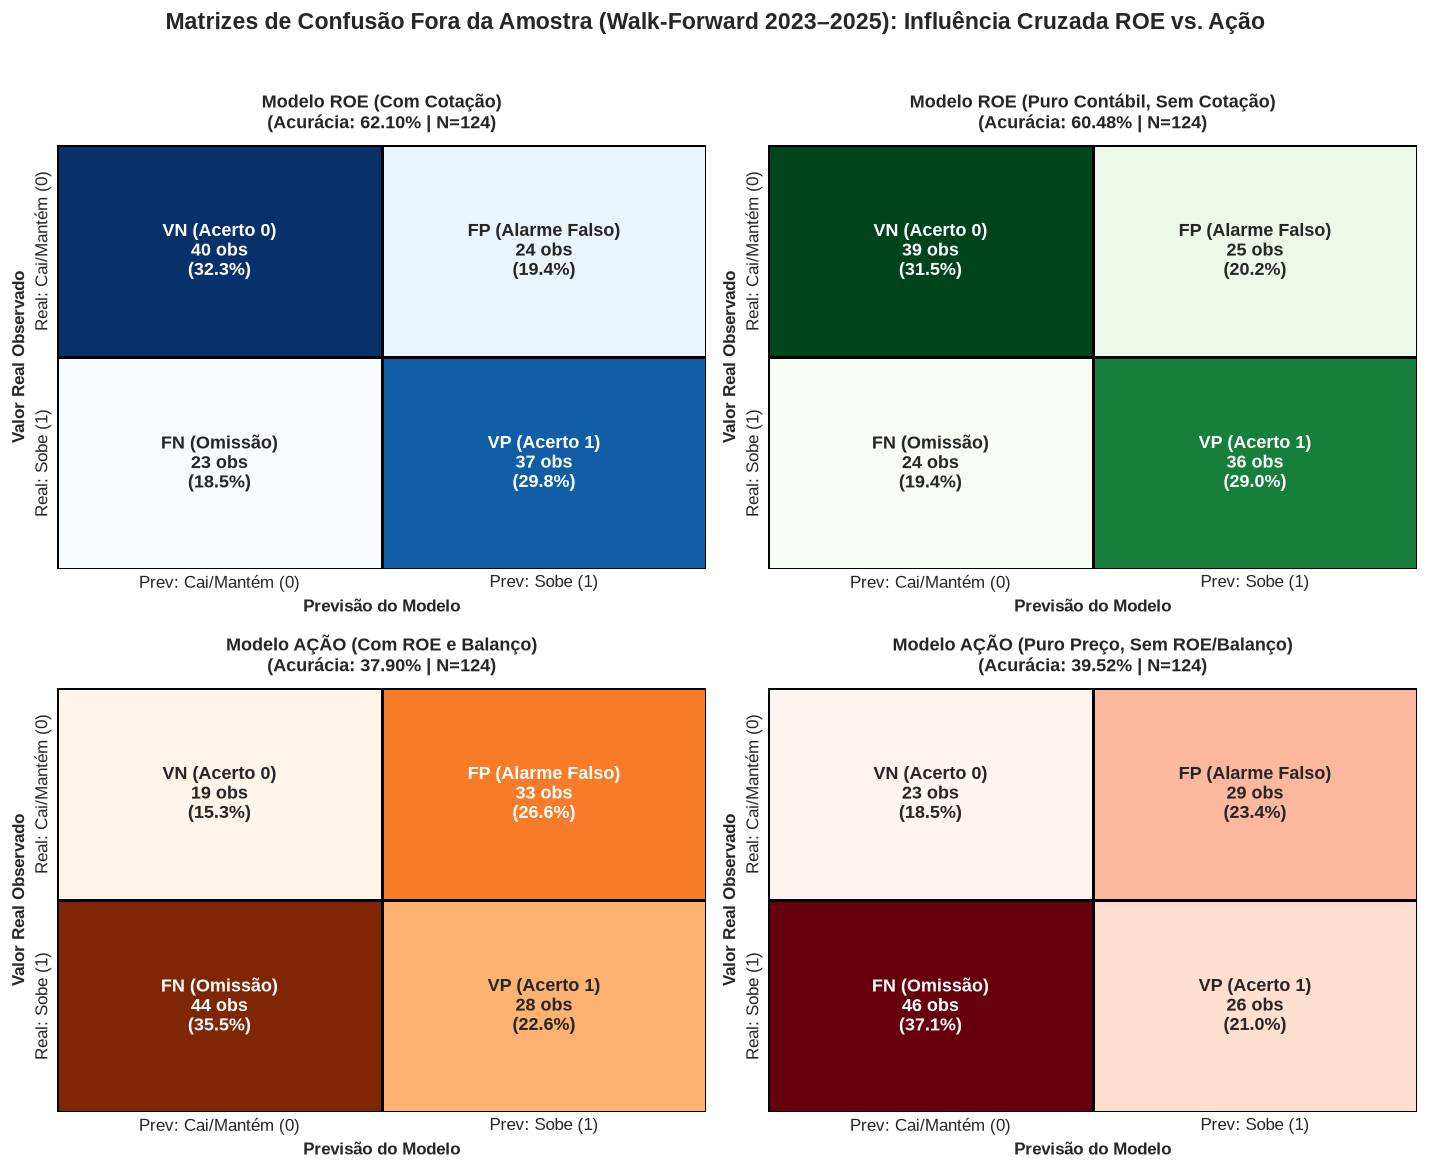

In [5]:
import seaborn as sns

# ==============================================================================
# 1. TESTE SEPARADO (ABLAÇÃO DE FEATURES): O ROE INFLUENCIA A AÇÃO E VICE-VERSA?
# ==============================================================================
features_roe_puro = ['LUCRO_LIQUIDO_BI', 'PATRIMONIO_LIQUIDO_BI', 'ROE'] + cluster_cols + macro_cols
features_acao_puro = ['COTACAO_FINAL_ANO'] + cluster_cols + macro_cols

experimentos = [
    ('Modelo ROE (Com Cotação)', features, 'ROE_SOBE'),
    ('Modelo ROE (Puro Contábil, Sem Cotação)', features_roe_puro, 'ROE_SOBE'),
    ('Modelo AÇÃO (Com ROE e Balanço)', features, 'ACAO_SOBE'),
    ('Modelo AÇÃO (Puro Preço, Sem ROE/Balanço)', features_acao_puro, 'ACAO_SOBE'),
]

resultados_ablacao = []
matrizes_guardadas = {}

for nome_exp, cols_exp, alvo_exp in experimentos:
    yt_all, yp_all = [], []
    for ano_alvo in [2023, 2024, 2025]:
        tr = df_modelo[df_modelo['ANO_ALVO'] < ano_alvo]
        te = df_modelo[df_modelo['ANO_ALVO'] == ano_alvo]
        
        mod = Pipeline([
            ('scaler', StandardScaler()),
            ('rf', RandomForestClassifier(
                n_estimators=100, max_depth=4, min_samples_split=5,
                random_state=42, class_weight='balanced'
            ))
        ])
        mod.fit(tr[cols_exp], tr[alvo_exp])
        pr = mod.predict(te[cols_exp])
        yt_all.extend(te[alvo_exp])
        yp_all.extend(pr)
    
    cm = confusion_matrix(yt_all, yp_all)
    matrizes_guardadas[nome_exp] = cm
    tn, fp, fn, tp = cm.ravel()
    
    resultados_ablacao.append({
        'Experimento': nome_exp,
        'Alvo': alvo_exp,
        'N_Features': len(cols_exp),
        'Acuracia': f"{accuracy_score(yt_all, yp_all):.2%}",
        'Precisao': f"{precision_score(yt_all, yp_all):.2%}",
        'Recall': f"{recall_score(yt_all, yp_all):.2%}",
        'F1_Score': f"{f1_score(yt_all, yp_all):.2%}",
        'Matriz_Confusao': f"[[{tn}, {fp}], [{fn}, {tp}]]"
    })

df_ablacao = pd.DataFrame(resultados_ablacao)
print("🔬 TABELA 3 — TESTE DE INFLUÊNCIA CRUZADA (ABLAÇÃO DE FEATURES ENTRE ROE E COTAÇÃO):")
print(df_ablacao.to_string(index=False))

# ==============================================================================
# 2. GRÁFICO DAS MATRIZES DE CONFUSÃO (ACUMULADO WALK-FORWARD N=124)
# ==============================================================================
fig_cm, axes = plt.subplots(2, 2, figsize=(12, 9.5))

titulos_cm = [
    ('Modelo ROE (Com Cotação)', 'Blues', ['Cai/Mantém (0)', 'Sobe (1)']),
    ('Modelo ROE (Puro Contábil, Sem Cotação)', 'Greens', ['Cai/Mantém (0)', 'Sobe (1)']),
    ('Modelo AÇÃO (Com ROE e Balanço)', 'Oranges', ['Cai/Mantém (0)', 'Sobe (1)']),
    ('Modelo AÇÃO (Puro Preço, Sem ROE/Balanço)', 'Reds', ['Cai/Mantém (0)', 'Sobe (1)'])
]

for ax, (chave, cmap_name, labels_classe) in zip(axes.ravel(), titulos_cm):
    cm_plot = matrizes_guardadas[chave]
    cm_pct = cm_plot / cm_plot.sum() * 100
    
    # Rótulos combinando contagem absoluta e percentual do total (N=124)
    annot_matrix = np.empty_like(cm_plot, dtype=object)
    tipos = [['VN (Acerto 0)', 'FP (Alarme Falso)'], ['FN (Omissão)', 'VP (Acerto 1)']]
    for i in range(2):
        for j in range(2):
            annot_matrix[i, j] = f"{tipos[i][j]}\n{cm_plot[i, j]} obs\n({cm_pct[i, j]:.1f}%)"
            
    sns.heatmap(
        cm_plot, annot=annot_matrix, fmt='', cmap=cmap_name, cbar=False, ax=ax,
        xticklabels=[f"Prev: {l}" for l in labels_classe],
        yticklabels=[f"Real: {l}" for l in labels_classe],
        annot_kws={'size': 10.5, 'weight': 'bold'}, linewidths=1.5, linecolor='black'
    )
    acc_val = np.trace(cm_plot) / np.sum(cm_plot) * 100
    ax.set_title(f"{chave}\n(Acurácia: {acc_val:.2f}% | N=124)", fontsize=11, fontweight='bold', pad=10)
    ax.set_xlabel('Previsão do Modelo', fontsize=10, fontweight='bold')
    ax.set_ylabel('Valor Real Observado', fontsize=10, fontweight='bold')

plt.suptitle('Matrizes de Confusão Fora da Amostra (Walk-Forward 2023–2025): Influência Cruzada ROE vs. Ação', fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 🧠 Interpretação Estatística e Teórica: O que a Comparação Antes vs. Depois Revela?

A Tabela 2 e o gráfico acima encerram a discussão metodológica aberta no Notebook 08 e demonstram três fatos essenciais:

---

### 1. O Colapso da Ilusão em `ACAO_SOBE` (De 76,92% com Leakage para 37,90% no Walk-Forward)
* **No Split Aleatório (Antes):** Ao sortear 25% das linhas ($N = 39$) misturando anos, o modelo atingia **76,92% de acurácia** (`F1 = 82,35%`, `Precisão = 91,30%`). Por quê? Porque ele já conhecia no treino o retorno do Ibovespa e do Dólar daquele mesmo ano e sabia que 71,79% das ações da amostra subiam quando a bolsa subia.
* **No Walk-Forward (Depois):** Quando obrigado a prever um ano inédito ($2023$, $2024$ e $2025$) usando apenas o passado, a acurácia cai para **37,90%** (`F1 = 42,11%`). Em cada virada de ano houve mudança abrupta de regime macroeconômico (ex: Ibovespa $+22,28\%$ em 2023 $\to$ $-10,37\%$ em 2024 $\to$ $+33,95\%$ em 2025). Sem olhar o futuro, prever preço anual com balanço do ano anterior perde para um chute ingênuo.

---

### 2. A Estabilidade do Fundamento Contábil (`ROE_SOBE`: 62,10% no Walk-Forward vs. 51,61% da Baseline)
O **ROE (*Return on Equity*)** mede a eficiência operacional com que a empresa remunera o patrimônio dos acionistas:

$$\text{ROE}_t = \frac{\text{Lucro Líquido}_t}{\text{Patrimônio Líquido}_t}$$

* Ao contrário do preço de tela, o ROE apresenta **62,10% de acurácia acumulada** nos 3 folds ($N = 124$), superando a baseline da classe majoritária em todos os anos testados:
  * **Fold 1 (2023):** `65,00%` vs `52,50%` da classe majoritária (+12,5 p.p. de ganho, `F1 = 58,82%`).
  * **Fold 2 (2024):** `65,85%` vs `51,22%` da classe majoritária (+14,6 p.p. de ganho, `F1 = 66,67%`).
  * **Fold 3 (2025):** `55,81%` vs `51,16%` da classe majoritária (+4,7 p.p. de ganho, `F1 = 57,78%`).
* **Cautela Estatística (Intervalo de Confiança):** Com $N = 124$ observações de teste no total, o erro-padrão binomial é $\approx 4,36\%$, situando o **Intervalo de Confiança de 95% (IC 95%) entre `53,6%` e `70,6%`**. Trata-se de um **sinal preditivo promissor e consistente** acima da baseline majoritária (51,6%), mas não de uma "prova determinística absoluta", dada a restrição natural de tamanho amostral.

Como sintetizou **Benjamin Graham**:
> *"No curto prazo, o mercado é uma **urna de votação** (movido por humor, medo, euforia e especulação). No longo prazo, o mercado é uma **balança de precisão** (movido pelo lucro e pela geração de valor real da empresa)."*


---
## 🔮 Projeção para 2026 (Com Dados Macroeconômicos de 2025 Auditados)

Para estimar a probabilidade de expansão do ROE em **2026**, treinamos o modelo com todos os 156 pares históricos consolidados (`2021->2022` até `2024->2025`) e aplicamos sobre os balanços fechados de **2025** ($47$ empresas), utilizando os **indicadores macroeconômicos oficiais realizados em 31/12/2025** (`Selic = 15,00%`, `IPCA = 4,26%`, `Ibovespa = +33,95%`, `Dólar = -11,36%`).


In [5]:
# 1. Treinar no histórico completo com gabarito (156 transições: 2021->2022 até 2024->2025)
treino_total = df_modelo.copy()

# 2. Balanços e cenário macro oficial de 2025 (entrada para prever o fechamento de 2026)
df_2025 = df_completo[df_completo['ANO'] == 2025].dropna(subset=features).copy()

X_train_full = treino_total[features]
y_train_roe_full = treino_total['ROE_SOBE']
X_2025 = df_2025[features]

modelo_roe_2026 = Pipeline([
    ('scaler', StandardScaler()),
    ('rf', RandomForestClassifier(
        n_estimators=100, max_depth=4, min_samples_split=5,
        random_state=42, class_weight='balanced'
    ))
])
modelo_roe_2026.fit(X_train_full, y_train_roe_full)

df_2025['PREV_ROE_2026'] = modelo_roe_2026.predict(X_2025)
df_2025['PROB_ROE_SUBIR_%'] = (modelo_roe_2026.predict_proba(X_2025)[:, 1] * 100).round(1)

ranking_2026 = df_2025[['TICKER', 'EMPRESA', 'SETOR', 'ROE', 'PROB_ROE_SUBIR_%', 'PREV_ROE_2026']].sort_values(
    by='PROB_ROE_SUBIR_%', ascending=False
)

print("🔮 TOP 10 EMPRESAS COM MAIOR PROBABILIDADE ESTIMADA DE EXPANSÃO DE ROE EM 2026:")
print(ranking_2026.head(10).to_string(index=False))


🔮 TOP 10 EMPRESAS COM MAIOR PROBABILIDADE ESTIMADA DE EXPANSÃO DE ROE EM 2026:
   TICKER                                 EMPRESA                                         SETOR       ROE  PROB_ROE_SUBIR_%  PREV_ROE_2026
 ALOS3.SA                              ALLOS S.A. Emp. Adm. Part. - Comércio (Atacado e Varejo)  0.068012              77.0              1
 AURE3.SA                      AUREN ENERGIA S.A.                              Energia Elétrica -0.040498              72.2              1
 CSNA3.SA                CIA SIDERURGICA NACIONAL                       Metalurgia e Siderurgia -0.095748              71.3              1
 VBBR3.SA                       VIBRA ENERGIA S/A                   Comércio (Atacado e Varejo)  0.095415              69.4              1
 GGBR4.SA                             GERDAU S.A.                       Metalurgia e Siderurgia  0.026366              68.5              1
 ENEV3.SA                               ENEVA S.A                              Energia 

## 🔍 Análise Crítica do Ranking 2026 e Limitações do Estudo

### 1. Por que empresas com ROE baixo ou negativo lideram as probabilidades de alta? (*Reversão à Média*)
Ao observar o Top 10 projetado para 2026 (*Allos*, *CSN*, *Auren*, *Vibra*, *Hapvida*, *Gerdau*, *Cogna*), nota-se que o modelo atribui maior probabilidade de subida ($\Delta \text{ROE} > 0$) a empresas que tiveram ROE comprimido ou negativo em 2025.
* **Processo de Ornstein-Uhlenbeck (Reversão à Média):** $\Delta \text{ROE}_{t+1} = \theta (\mu - \text{ROE}_t) + \varepsilon_t$. Empresas sobreviventes que sofreram forte compressão de margens sob Selic de 15% tendem a executar programas de *turnaround* (corte de custos e desalavancagem).
* **Efeito Base na Derivada Binária:** Para uma companhia que operou com ROE negativo (ex: $-4\%$), basta estancar o prejuízo para que $\text{ROE}_{t+1} > \text{ROE}_t$ (`ROE_SOBE = 1`). Já para uma líder que operou com ROE de $36\%$ (como a WEG), qualquer acomodação normal para $34\%$ representa queda (`ROE_SOBE = 0`).

### 2. Escopo de Machine Learning Tabular vs. Finanças Quantitativas (*Quant*)
* **Amostra Curta ($T = 5$ anos, $N_{\text{teste}} = 124$):** Com apenas 3 folds anuais de teste e treinos crescendo de 32 para 113 observações, o intervalo de confiança de 95% da acurácia do ROE (`53,6%` a `70,6%`) reflete a incerteza inerente a bases anuais enxutas.
* **Diferença para o Mercado Quant:** Fundos quantitativos operam sinais intradiários, dados alternativos e milhares de observações por ativo. Aqui, demonstramos como estruturar um pipeline **metodologicamente honesto, livre de *Data Leakage* e auditado contra baselines reais** usando demonstrações contábeis públicas da CVM.
